## Gaussian 4D Synthetic Dataset for OCSMM-SHAP-IQ

### Same Mean

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np

np.random.seed(47)

# Parameters
num_inlier_groups = 20
num_outlier_groups = 3
samples_per_group = 30
dim = 4

# Function to generate a group with a custom x-y covariance
def generate_group(n_samples, xy_cov=0.8):
    # Covariance matrix
    cov = np.array([
        [1.0, xy_cov, 0.0, 0.0],  # x
        [xy_cov, 1.0, 0.0, 0.0],  # y
        [0.0, 0.0, 1.0, 0.0],     # z1
        [0.0, 0.0, 0.0, 1.0]      # z2
    ])
    mean = np.zeros(dim)
    return np.random.multivariate_normal(mean, cov, size=n_samples)

# Create inlier and outlier groups
inlier_groups = [generate_group(samples_per_group, xy_cov=0.8) for _ in range(num_inlier_groups)]
outlier_groups = [generate_group(samples_per_group, xy_cov=-0.8) for _ in range(num_outlier_groups)]

# Stack group data
inlier_data = np.vstack(inlier_groups)
outlier_data = np.vstack(outlier_groups)

# Covariance summaries
inlier_cov = np.cov(inlier_data, rowvar=False)
outlier_cov = np.cov(outlier_data, rowvar=False)

# Print results
print("Aggregated Covariance Matrix (Inliers - Positively Correlated x-y):")
print(inlier_cov)

print("\nAggregated Covariance Matrix (Outliers - Negatively Correlated x-y):")
print(outlier_cov)

# Combined dataset
datasets = inlier_groups + outlier_groups

print(f"\nTotal number of groups: {len(datasets)}")
print(f"Shape of first group: {datasets[0].shape}") 


Aggregated Covariance Matrix (Inliers - Positively Correlated x-y):
[[0.99652577 0.7594112  0.03398547 0.02891315]
 [0.7594112  0.94554517 0.04869115 0.00810532]
 [0.03398547 0.04869115 1.00817172 0.0198465 ]
 [0.02891315 0.00810532 0.0198465  0.93162142]]

Aggregated Covariance Matrix (Outliers - Negatively Correlated x-y):
[[ 0.82000958 -0.71599368 -0.08798532 -0.08031832]
 [-0.71599368  1.02690026 -0.01229892  0.11940435]
 [-0.08798532 -0.01229892  0.8833668  -0.0038839 ]
 [-0.08031832  0.11940435 -0.0038839   0.90898475]]

Total number of groups: 23
Shape of first group: (30, 4)


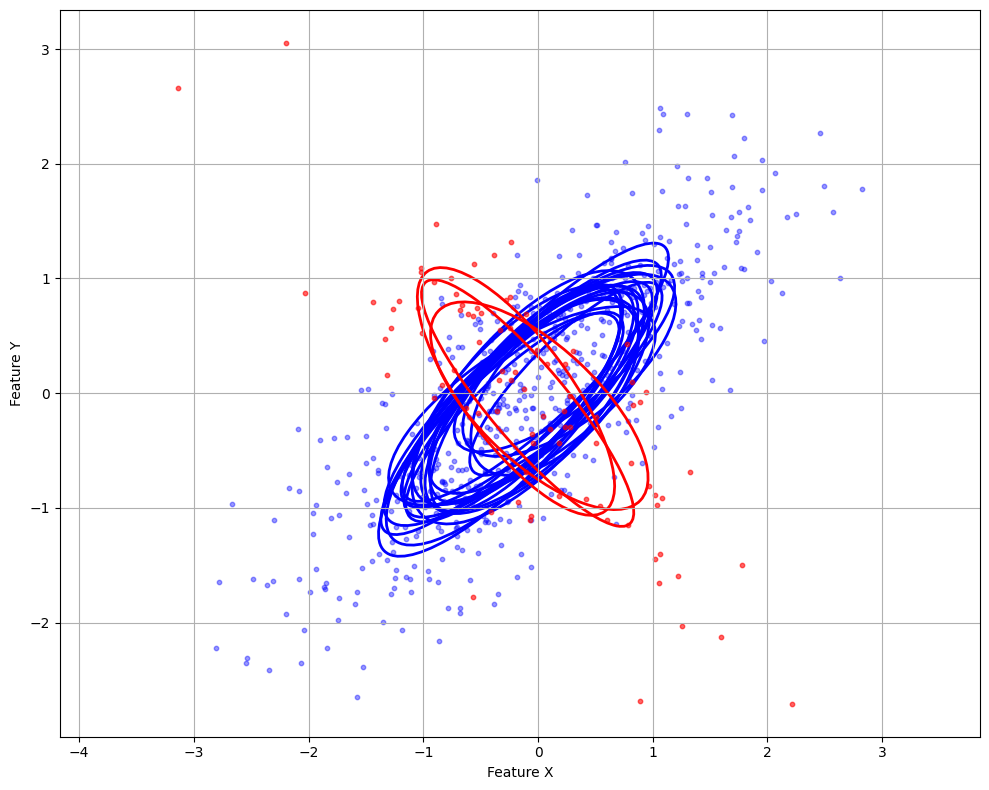

In [3]:

# Function to draw ellipse for a 2D Gaussian
from matplotlib import pyplot as plt
from matplotlib.patches import Ellipse


def draw_ellipse(ax, data, color='blue'):
    xy = data[:, :2]
    cov = np.cov(xy, rowvar=False)
    mean = np.mean(xy, axis=0)

    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * np.sqrt(vals)

    ellipse = Ellipse(xy=mean, width=width, height=height, angle=angle,
                      edgecolor=color, facecolor='none', lw=2)
    ax.add_patch(ellipse)

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))

# Inliers
for group in inlier_groups:
    ax.scatter(group[:, 0], group[:, 1], color='blue', alpha=0.4, s=10)
    draw_ellipse(ax, group, color='blue')

# Outliers
for group in outlier_groups:
    ax.scatter(group[:, 0], group[:, 1], color='red', alpha=0.6, s=10)
    draw_ellipse(ax, group, color='red')

# ax.set_title("Group-wise Ellipses with Random Means\nBlue = Inliers (Pos Corr), Red = Outliers (Neg Corr)")
ax.set_xlabel("Feature X")
ax.set_ylabel("Feature Y")
ax.grid(True)
plt.tight_layout()
plt.axis("equal")
plt.show()


In [4]:
datasets

[array([[ 0.60197643,  1.00700842,  0.92420797,  1.30590636],
        [ 0.7401588 ,  1.26106392, -1.01278675,  1.79776072],
        [-0.0696424 ,  0.62870214, -1.39372706, -0.59247057],
        [ 0.63310778,  1.13588354,  0.43660623, -0.94315644],
        [-0.69898778, -0.66623039, -1.32274841,  0.08766226],
        [ 1.6873778 ,  1.79390143,  0.47623723,  0.32749647],
        [ 1.51778669,  0.11852376,  0.42288937,  0.9074445 ],
        [ 1.91108058,  1.22755413, -0.46267435,  0.32137526],
        [ 0.30714212,  0.28820245,  0.4994227 , -1.01785189],
        [-0.13054279,  0.04119559, -1.91252729, -1.17085876],
        [-0.01448271, -0.59659323,  0.15786114, -1.13100016],
        [ 0.44726734,  0.96799715,  1.96638482, -0.20421309],
        [ 0.88706805,  1.11936673,  0.27412325,  0.55104937],
        [ 0.11124784, -0.48292172, -2.08892706, -0.11352871],
        [-0.35711477, -0.16626884,  0.41674633,  0.42760686],
        [ 2.63280929,  1.00380451,  1.26964413, -0.18007256],
        

In [5]:
from src.ocsmm.OneClassSMMClassifier import OneClassSMMClassifier
classifier = OneClassSMMClassifier(nu=0.2) 
classifier.fit(datasets[:20])

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [6]:
decision, y_pred  = classifier.predict(datasets)

Calculating kappa.

calculating rho.

0.8596895558883365


In [7]:
y_pred

array([ 1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1., -1., -1., -1.])

In [8]:
decision

array([ 0.00690696,  0.00130966,  0.02248698,  0.02362282,  0.00130965,
        0.02891458,  0.00851138,  0.01967784,  0.0119286 ,  0.0317119 ,
       -0.00916809,  0.00130958,  0.02274099,  0.00131063,  0.01022654,
        0.00130964,  0.0013093 ,  0.01935796,  0.00130962,  0.01176567,
       -0.05212817, -0.04984555, -0.07023532])

In [9]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[10, 20, 21, 22]

In [10]:
from src.explanation_algorithms.OCSMMSHAPIQ_Exact import OCSMMSHAPIQ

shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[20],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)
interactions_per_group.dict_values

100%|██████████| 16/16 [00:00<00:00, 75.69it/s]


[ 0.12499992 -0.22578793  0.10892258 -0.0525863   0.07305724 -0.46174272
  0.23547766  0.28562707 -0.24177909 -0.26703601  0.04699555]


{(): 0.12499991630801169,
 (0,): -0.2257879294408758,
 (1,): 0.10892257788872041,
 (2,): -0.05258629582641037,
 (3,): 0.07305723771903452,
 (0, 1): -0.46174272327403665,
 (0, 2): 0.23547766302334494,
 (0, 3): 0.28562707163522033,
 (1, 2): -0.2417790900688176,
 (1, 3): -0.2670360075090066,
 (2, 3): 0.046995549404404556}

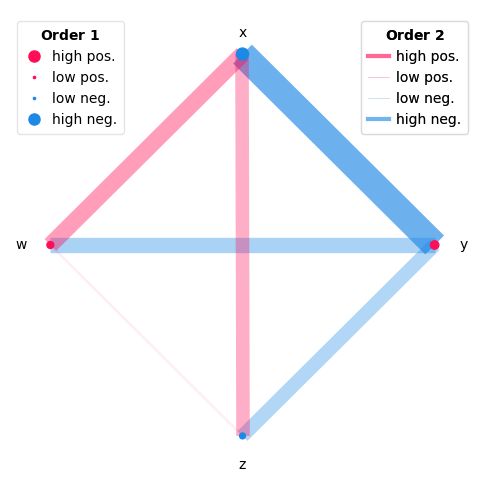

In [11]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

In [12]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[21],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)
interactions_per_group.dict_values

100%|██████████| 16/16 [00:00<00:00, 30066.70it/s]


[ 0.12499992 -0.05437598 -0.16154974 -0.03848228  0.12847178 -0.29627001
  0.05385477  0.0124543   0.03379873 -0.02050643  0.00862348]


{(): 0.12499991630801169,
 (0,): -0.05437597902550597,
 (1,): -0.16154974083814808,
 (2,): -0.03848227511527444,
 (3,): 0.1284717752082208,
 (0, 1): -0.2962700098117067,
 (0, 2): 0.053854774496786065,
 (0, 3): 0.012454297657789357,
 (1, 2): 0.03379872679652036,
 (1, 3): -0.02050642831719477,
 (2, 3): 0.008623479745698938}

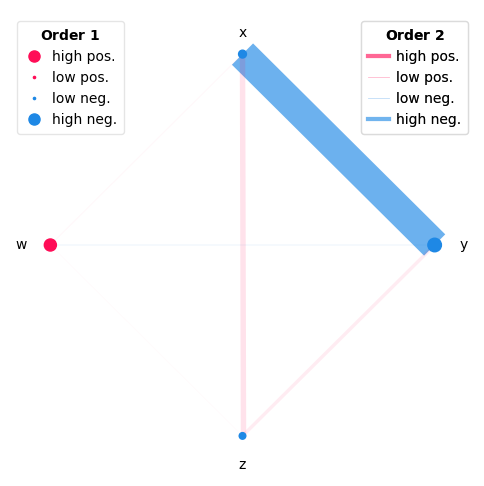

In [13]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

In [14]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[22],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)


100%|██████████| 16/16 [00:00<00:00, 30643.32it/s]


[ 0.12499992 -0.04792724  0.04599501 -0.11100899  0.0150498  -0.53985064
 -0.17808397 -0.02775966 -0.10688466 -0.17083445  0.20492743]


In [15]:
interactions_per_group.dict_values

{(): 0.12499991630801169,
 (0,): -0.047927243935501275,
 (1,): 0.04599500613773055,
 (2,): -0.11100898975887118,
 (3,): 0.015049796750571288,
 (0, 1): -0.539850640406523,
 (0, 2): -0.17808397350954627,
 (0, 3): -0.027759660652555536,
 (1, 2): -0.10688465800245257,
 (1, 3): -0.170834451568895,
 (2, 3): 0.20492742549391313}

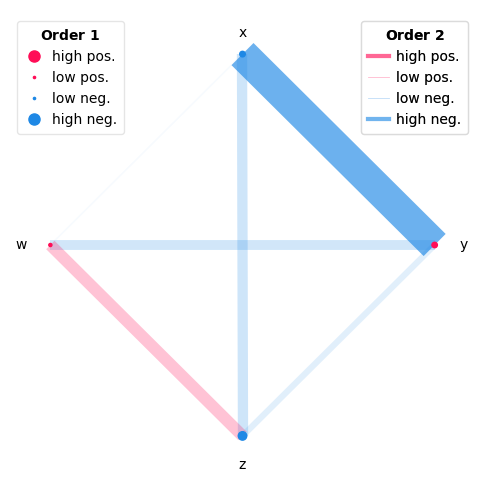

In [16]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

In [17]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)      # the other natural outlier
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[10],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)


100%|██████████| 16/16 [00:00<00:00, 32435.41it/s]


[ 0.12499992  0.02812902  0.0313554   0.03369132  0.03182319 -0.03323373
 -0.0367481  -0.03393469 -0.0415757  -0.03877477 -0.04227699]


In [18]:
interactions_per_group.dict_values

{(): 0.12499991630801169,
 (0,): 0.028129023215635627,
 (1,): 0.03135540200337354,
 (2,): 0.03369132098079758,
 (3,): 0.03182319093970729,
 (0, 1): -0.033233730263629774,
 (0, 2): -0.03674810291155277,
 (0, 3): -0.03393469080293945,
 (1, 2): -0.04157570183105326,
 (1, 3): -0.038774769220943785,
 (2, 3): -0.0422769853430636}

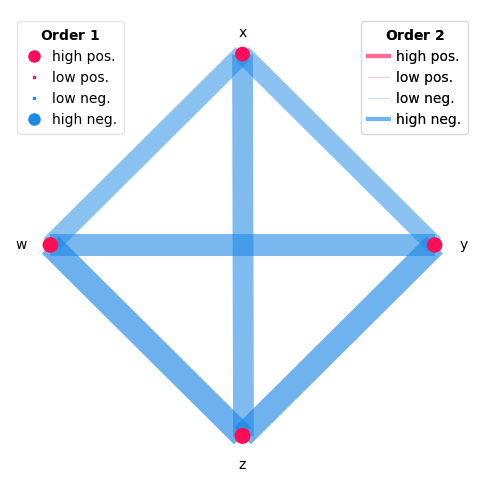

In [19]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

In [20]:
# inlier 
shapiq = OCSMMSHAPIQ(n=4, max_order=2)      
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[0],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)

100%|██████████| 16/16 [00:00<00:00, 29498.40it/s]


[ 0.12499992  0.06149537 -0.0859577   0.071214   -0.06818832  0.01161237
  0.01674093 -0.11489509  0.11168989  0.13576634 -0.0422913 ]


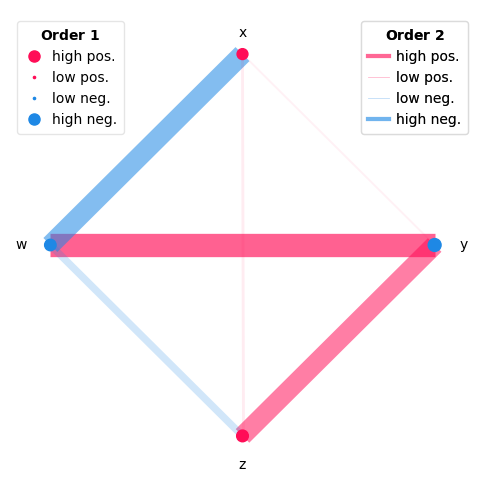

In [21]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

### Different Means

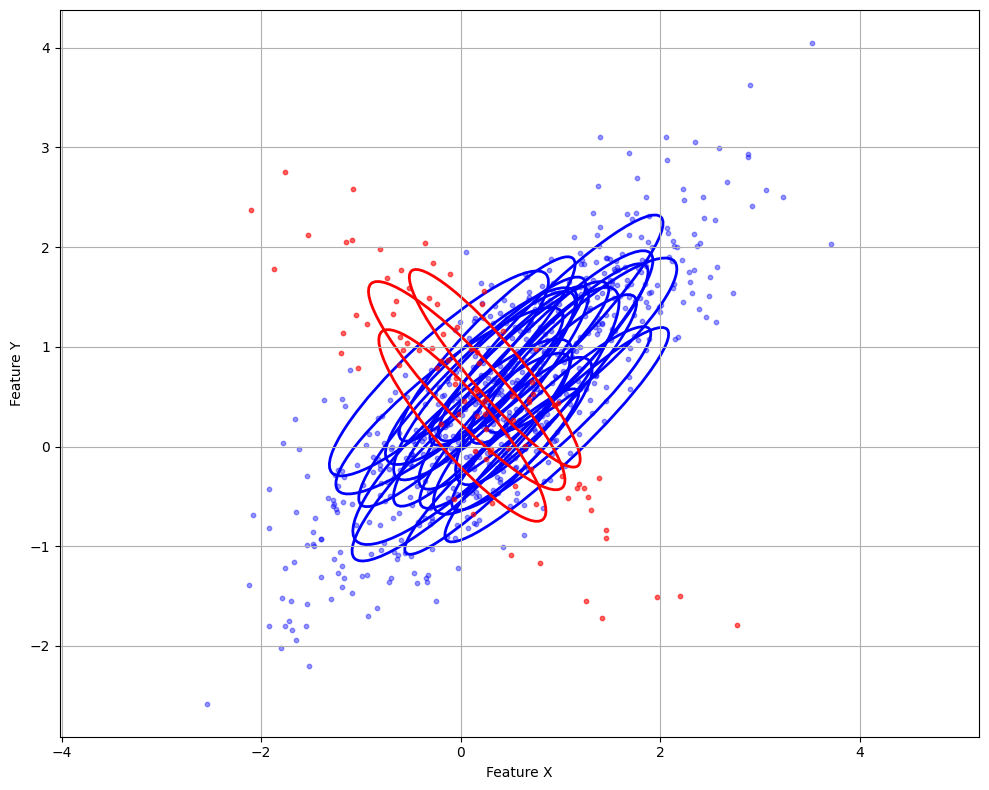

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

np.random.seed(47)

# Parameters
num_inlier_groups = 20
num_outlier_groups = 3
samples_per_group = 30
dim = 4

# Function to generate a group with custom x-y correlation and random mean
def generate_group(n_samples, xy_cov=0.9):
    cov = np.array([
        [1.0, xy_cov, 0.0, 0.0],
        [xy_cov, 1.0, 0.0, 0.0],
        [0.0, 0.0, 1.0, 0.0],
        [0.0, 0.0, 0.0, 1.0],
    ])
    mean = np.random.uniform(0, 1, size=dim)
    data = np.random.multivariate_normal(mean, cov, size=n_samples)
    return data

# Generate data
inlier_groups = [generate_group(samples_per_group, xy_cov=0.9) for _ in range(num_inlier_groups)]
outlier_groups = [generate_group(samples_per_group, xy_cov=-0.9) for _ in range(num_outlier_groups)]

# Function to draw ellipse for a 2D Gaussian
def draw_ellipse(ax, data, color='blue'):
    xy = data[:, :2]
    cov = np.cov(xy, rowvar=False)
    mean = np.mean(xy, axis=0)

    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * np.sqrt(vals)

    ellipse = Ellipse(xy=mean, width=width, height=height, angle=angle,
                      edgecolor=color, facecolor='none', lw=2)
    ax.add_patch(ellipse)

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))

# Inliers
for group in inlier_groups:
    ax.scatter(group[:, 0], group[:, 1], color='blue', alpha=0.4, s=10)
    draw_ellipse(ax, group, color='blue')

# Outliers
for group in outlier_groups:
    ax.scatter(group[:, 0], group[:, 1], color='red', alpha=0.6, s=10)
    draw_ellipse(ax, group, color='red')
    

# ax.set_title("Group-wise Ellipses with Random Means\nBlue = Inliers (Pos Corr), Red = Outliers (Neg Corr)")
ax.set_xlabel("Feature X")
ax.set_ylabel("Feature Y")
ax.grid(True)
plt.tight_layout()
plt.axis("equal")
plt.show()


In [23]:
datasets = inlier_groups + outlier_groups

In [24]:
len(datasets)

23

In [25]:
from src.ocsmm.OneClassSMMClassifier import OneClassSMMClassifier
classifier = OneClassSMMClassifier(nu=0.25)  
classifier.fit(datasets[:20])

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [26]:
decision, y_pred = classifier.predict(datasets)

Calculating kappa.

calculating rho.

0.7585847619065592


In [27]:
decision

array([ 0.00093152,  0.02795837,  0.00093175,  0.05003843,  0.01893115,
        0.01007408,  0.01963188,  0.00093155,  0.00921678,  0.02299021,
       -0.00368682,  0.0009318 ,  0.06164033,  0.00093169,  0.00327857,
        0.00093152, -0.00283496,  0.0190094 ,  0.04920681,  0.00093195,
       -0.03999411, -0.09077259, -0.06163258])

In [28]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[10, 16, 20, 21, 22]

In [29]:
decision.mean() + classifier.rho

np.float64(0.7629141855922033)

In [30]:
from src.explanation_algorithms.OCSMMSHAPIQ_Exact import OCSMMSHAPIQ

shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[20],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)

100%|██████████| 16/16 [00:00<00:00, 74.03it/s]


[ 0.11111105 -0.10201478  0.01120135  0.14952964 -0.02799974 -0.25006796
  0.08067758  0.35370451 -0.01532174  0.31744148 -0.06125856]


In [31]:
interactions_per_group.dict_values

{(): 0.11111104501321459,
 (0,): -0.10201478121317667,
 (1,): 0.01120135472927168,
 (2,): 0.14952963513259052,
 (3,): -0.02799973602967559,
 (0, 1): -0.25006795751128535,
 (0, 2): 0.08067757835149558,
 (0, 3): 0.3537045137806844,
 (1, 2): -0.015321742947860303,
 (1, 3): 0.3174414751466671,
 (2, 3): -0.061258562100713676}

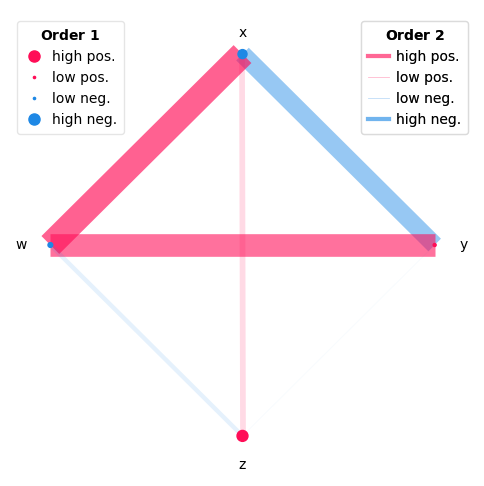

In [32]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

In [33]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[21],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)

100%|██████████| 16/16 [00:00<00:00, 33554.43it/s]


[ 0.11111105 -0.03856254 -0.1548594   0.02292716  0.18232276 -0.22144011
  0.03265008  0.09389397  0.21994888  0.17513922 -0.13054245]


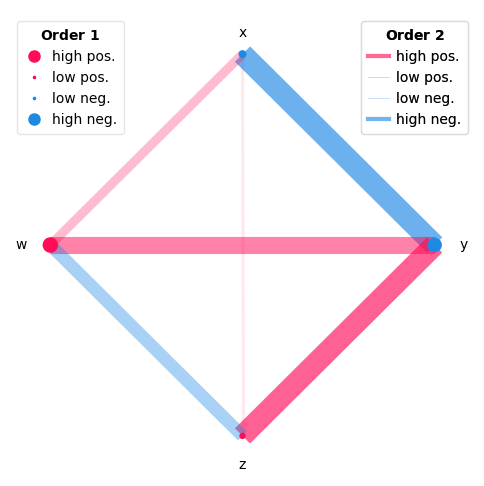

In [34]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

In [35]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[22],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)


100%|██████████| 16/16 [00:00<00:00, 29064.04it/s]


[ 0.11111105  0.00978482 -0.07487975  0.015503    0.09481251 -0.27310338
  0.24229645  0.00283718  0.13801833  0.10370672 -0.01328788]


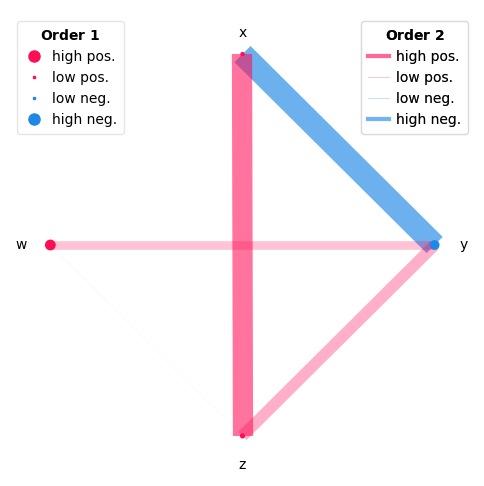

In [36]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

In [37]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[10],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)


100%|██████████| 16/16 [00:00<00:00, 30925.74it/s]


[ 0.11111105  0.03361676  0.01958364  0.01392273  0.02176366 -0.04287026
 -0.03437705 -0.0461296  -0.01332758 -0.02508296 -0.01658846]


In [38]:
interactions_per_group.dict_values

{(): 0.11111104501321459,
 (0,): 0.03361675577776992,
 (1,): 0.019583641142192975,
 (2,): 0.013922733644596235,
 (3,): 0.02176366419534378,
 (0, 1): -0.04287026148134158,
 (0, 2): -0.03437704843081971,
 (0, 3): -0.04612960215019508,
 (1, 2): -0.01332758180979353,
 (1, 3): -0.025082956065361102,
 (2, 3): -0.01658845967431703}

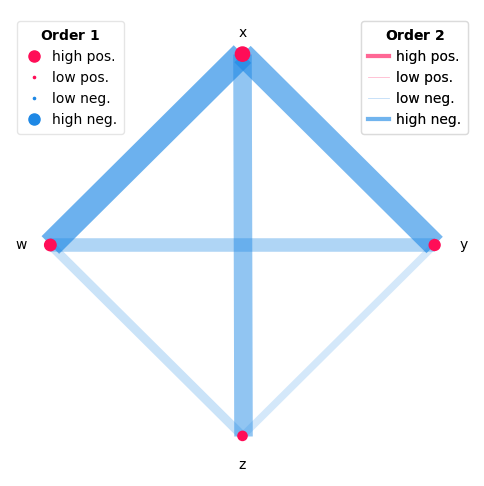

In [39]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

In [40]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[16],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)

100%|██████████| 16/16 [00:00<00:00, 28814.45it/s]


[ 0.11111105  0.0129918   0.02754777  0.03034743  0.01799648 -0.01696912
 -0.02115619 -0.00261927 -0.04298802 -0.02445808 -0.02867546]


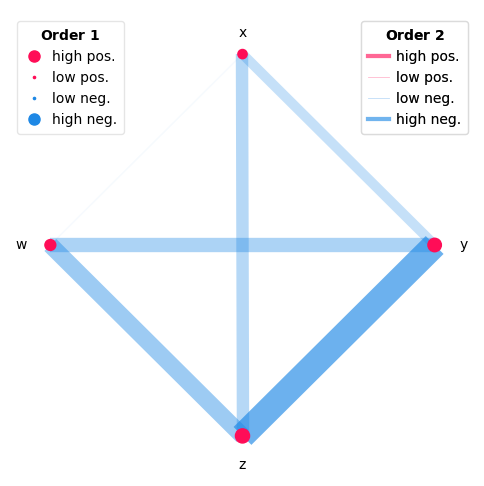

In [41]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

## x has correlation with y, z, and w

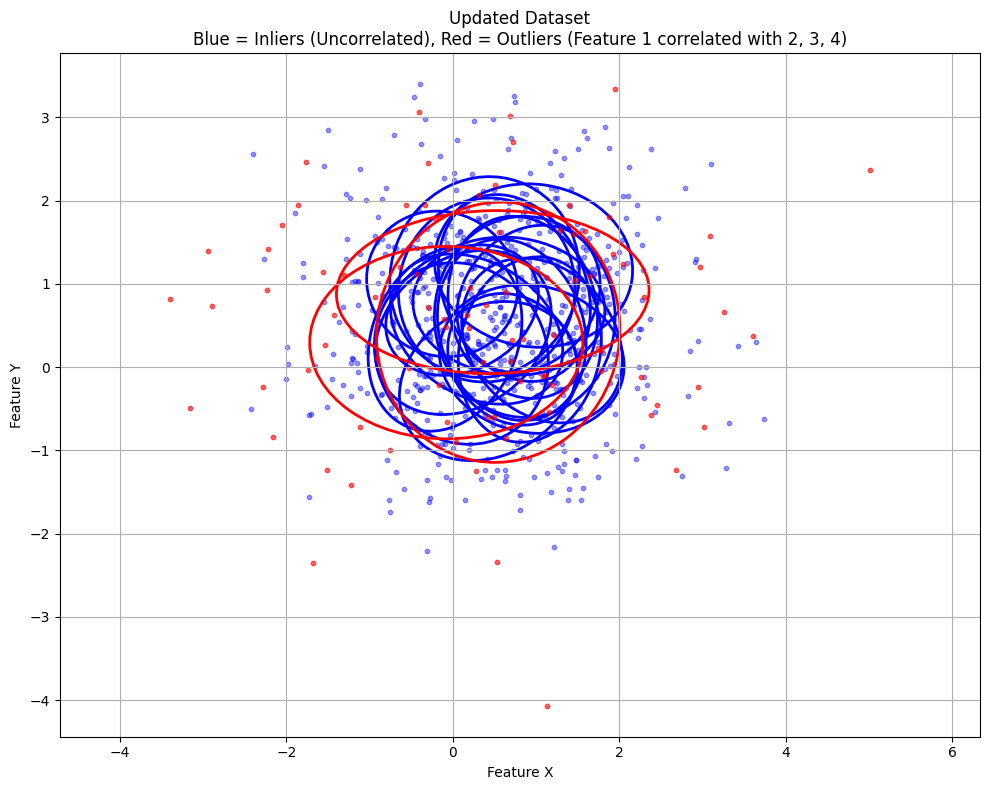

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

np.random.seed(47)

# Parameters
num_inlier_groups = 20
num_outlier_groups = 3
samples_per_group = 30
dim = 4

# Function to generate a group with custom x-y correlation and random mean
def generate_group(n_samples, cov_matrix):
    mean = np.random.uniform(0, 1, size=dim)
    data = np.random.multivariate_normal(mean, cov_matrix, size=n_samples)
    return data

# Covariance matrix for inliers: uncorrelated
inlier_cov = np.eye(dim)

# Covariance matrix for outliers: feature 0 highly correlated with 1, 2, 3
outlier_cov = np.array([
    [1.0, 1.9, 1.9, 1.9],
    [1.9, 1.0, 0.0, 0.0],
    [1.9, 0.0, 1.0, 0.0],
    [1.9, 0.0, 0.0, 1.0],
])

# Generate data
inlier_groups = [generate_group(samples_per_group, inlier_cov) for _ in range(num_inlier_groups)]
outlier_groups = [generate_group(samples_per_group, outlier_cov) for _ in range(num_outlier_groups)]

# Function to draw ellipse for a 2D Gaussian
def draw_ellipse(ax, data, color='blue'):
    xy = data[:, :2]
    cov = np.cov(xy, rowvar=False)
    mean = np.mean(xy, axis=0)

    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * np.sqrt(vals)

    ellipse = Ellipse(xy=mean, width=width, height=height, angle=angle,
                      edgecolor=color, facecolor='none', lw=2)
    ax.add_patch(ellipse)

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))

# Inliers
for group in inlier_groups:
    ax.scatter(group[:, 0], group[:, 1], color='blue', alpha=0.4, s=10)
    draw_ellipse(ax, group, color='blue')

# Outliers
for group in outlier_groups:
    ax.scatter(group[:, 0], group[:, 1], color='red', alpha=0.6, s=10)
    draw_ellipse(ax, group, color='red')

ax.set_title("Updated Dataset\nBlue = Inliers (Uncorrelated), Red = Outliers (Feature 1 correlated with 2, 3, 4)")
ax.set_xlabel("Feature X")
ax.set_ylabel("Feature Y")
ax.grid(True)
plt.tight_layout()
plt.axis("equal")
plt.show()


In [43]:
datasets = inlier_groups + outlier_groups

In [44]:
from src.ocsmm.OneClassSMMClassifier import OneClassSMMClassifier
classifier = OneClassSMMClassifier(nu=0.2)  
classifier.fit(datasets[:20])

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [45]:
decision = classifier.predict(datasets)

Calculating kappa.

calculating rho.

0.7549906667402532


In [46]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[10, 16, 20, 21, 22]

In [47]:
from src.explanation_algorithms.OCSMMSHAPIQ_Exact import OCSMMSHAPIQ

shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[21],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)

100%|██████████| 16/16 [00:00<00:00, 72.31it/s]


[ 0.14285711  0.49477001  0.00951091 -0.28717625 -0.19720206 -0.51670941
 -0.44531836 -0.51455907  0.22483689  0.19463067  0.48416793]


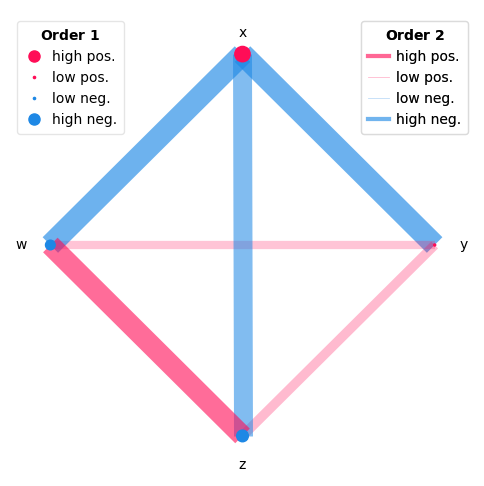

In [48]:
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

100%|██████████| 16/16 [00:00<00:00, 39199.10it/s]


[ 0.14285711  0.43398851 -0.21644557 -0.09490848 -0.12154042 -0.21675447
 -0.7200084  -0.71745915  0.25058406  0.38402998  0.01317052]


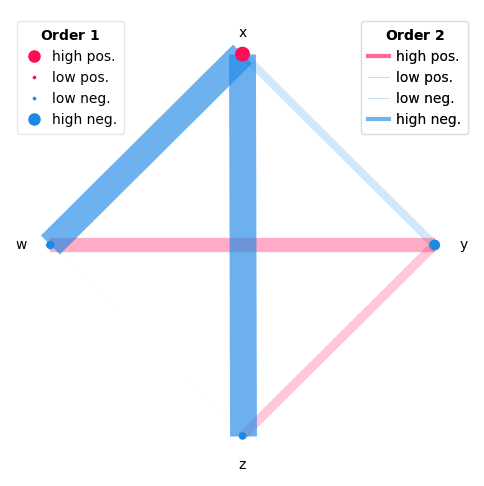

In [49]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[22],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)

100%|██████████| 16/16 [00:00<00:00, 29127.11it/s]


[ 0.14285711  0.44500516 -0.1290718  -0.15493395 -0.1124802  -0.1509059
 -0.24906315 -0.32126266  0.6198426   0.567638    0.3738608 ]


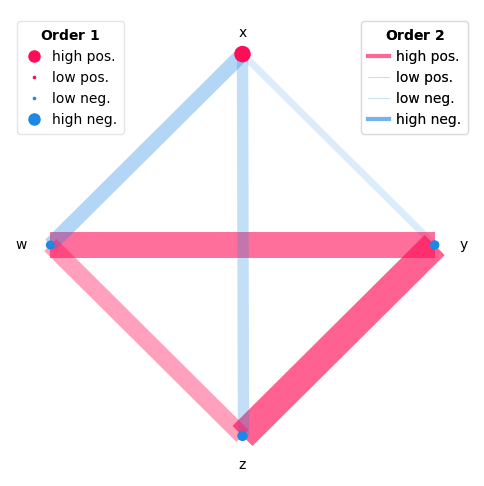

In [50]:
shapiq = OCSMMSHAPIQ(n=4, max_order=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[20],
    X_train=datasets,  
    model=classifier,
    regularization=1e-6)
interactions_per_group.plot_network(feature_names=['x', 'y', 'z', 'w'], show=True)